# 📊 Dataset Information

**Note:** The dataset for this project is **not included in this repository** to keep the repository lightweight.  

You can download the dataset from **Kaggle** using the link below:  

[Download The Network Security Telemetry Dataset](https://www.kaggle.com/datasets/philipfranklin/cyber-attack-escalation)  

Please make sure to place the downloaded CSV file in the same directory as this notebook before running any code.

# Importing

## Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.metrics import precision_score, recall_score, f1_score, balanced_accuracy_score

/kaggle/input/datasets/philipfranklin/cyber-attack-escalation/dataset.csv


## Import CSV And convert to DataFrame

In [2]:
df = pd.read_csv('dataset.csv')

# Preprocessing

## Frist five row

In [3]:
pd.set_option('display.max_columns', None)
df.head()

,observation_id,timestamp,network_node_id,network_zone,activity_session_id,failed_login_attempts,successful_login_attempts,authentication_failure_rate,unique_source_ips,unique_destination_ips,inbound_traffic_mb,outbound_traffic_mb,outbound_inbound_ratio,average_packet_size_bytes,unusual_port_connections,connection_attempts,connection_failure_rate,privilege_escalation_attempts,unauthorized_access_attempts,suspicious_process_count,security_alert_count,previous_security_alerts,session_duration_minutes,off_hours_activity,data_transfer_deviation,threat_intelligence_score,network_load_percentage,hour_of_day,day_of_week,is_weekend,escalation_within_15min
0,1,2025-01-01 07:45:00,NODE_019,Research,SES_019_00001,0,2,0.000000,3,19,522.568,305.967,0.585507,879.18,0,79,0.075949,0,0,0,0,1,62.47,1,1.2641,15.47,23.31,7,2,0,0
1,2,2025-01-01 07:50:00,NODE_019,Research,SES_019_00001,0,4,0.000000,3,13,72.341,62.448,0.863245,729.02,0,68,0.014706,0,0,0,1,1,68.57,1,-2.5980,0.00,27.36,7,2,0,0
2,3,2025-01-01 07:55:00,NODE_019,Research,SES_019_00001,0,2,0.000000,4,14,444.866,173.787,0.390650,745.92,0,120,0.058333,0,0,1,0,2,73.28,1,0.6131,28.16,29.73,7,2,0,0
3,4,2025-01-01 08:00:00,NODE_019,Research,SES_019_00001,1,1,0.500000,7,22,373.934,200.284,0.535613,883.95,1,161,0.068323,0,0,0,0,2,79.37,0,0.4530,15.35,31.94,8,2,0,0
4,5,2025-01-01 08:05:00,NODE_002,Finance,SES_002_00002,1,6,0.142857,6,4,49.986,14.097,0.282019,712.78,0,112,0.017857,0,0,0,0,3,12.72,0,1.7360,17.21,31.95,8,2,0,0


## last Five row

In [4]:
df.tail()

,observation_id,timestamp,network_node_id,network_zone,activity_session_id,failed_login_attempts,successful_login_attempts,authentication_failure_rate,unique_source_ips,unique_destination_ips,inbound_traffic_mb,outbound_traffic_mb,outbound_inbound_ratio,average_packet_size_bytes,unusual_port_connections,connection_attempts,connection_failure_rate,privilege_escalation_attempts,unauthorized_access_attempts,suspicious_process_count,security_alert_count,previous_security_alerts,session_duration_minutes,off_hours_activity,data_transfer_deviation,threat_intelligence_score,network_load_percentage,hour_of_day,day_of_week,is_weekend,escalation_within_15min
24995,24996,2025-05-30 00:30:00,NODE_013,Guest_Network,SES_013_00028,6,2,0.750000,13,14,87.452,17.871,0.204352,511.79,7,87,0.172414,0,0,0,1,3,118.64,1,0.5619,18.20,25.48,0,4,0,0
24996,24997,2025-05-30 00:35:00,NODE_013,Guest_Network,SES_013_00028,11,2,0.846154,23,16,73.626,18.591,0.252506,555.94,0,71,0.098592,0,0,0,1,4,121.02,1,0.3500,18.90,23.05,0,4,0,1
24997,24998,2025-05-30 00:40:00,NODE_013,Guest_Network,SES_013_00028,13,1,0.928571,27,17,43.072,8.248,0.191493,570.45,7,140,0.114286,0,0,0,3,5,129.78,1,-0.6021,37.39,28.33,0,4,0,1
24998,24999,2025-05-30 00:45:00,NODE_013,Guest_Network,SES_013_00028,23,2,0.920000,33,26,73.271,16.058,0.219159,416.77,4,143,0.153846,0,1,0,3,8,131.48,1,0.3274,31.08,30.48,0,4,0,1
24999,25000,2025-05-30 00:50:00,NODE_013,Guest_Network,SES_013_00028,8,3,0.727273,29,20,86.389,20.601,0.238468,553.64,1,54,0.185185,0,0,0,0,10,137.95,1,0.6397,21.05,20.65,0,4,0,0


## Shape of our dataset

In [5]:
df.shape

(25000, 31)

## List out all columns

In [6]:
df.columns

Index(['observation_id', 'timestamp', 'network_node_id', 'network_zone',
       'activity_session_id', 'failed_login_attempts',
       'successful_login_attempts', 'authentication_failure_rate',
       'unique_source_ips', 'unique_destination_ips', 'inbound_traffic_mb',
       'outbound_traffic_mb', 'outbound_inbound_ratio',
       'average_packet_size_bytes', 'unusual_port_connections',
       'connection_attempts', 'connection_failure_rate',
       'privilege_escalation_attempts', 'unauthorized_access_attempts',
       'suspicious_process_count', 'security_alert_count',
       'previous_security_alerts', 'session_duration_minutes',
       'off_hours_activity', 'data_transfer_deviation',
       'threat_intelligence_score', 'network_load_percentage', 'hour_of_day',
       'day_of_week', 'is_weekend', 'escalation_within_15min'],
      dtype='object')

## Datatype of each columns

In [7]:
df.dtypes

observation_id                     int64
timestamp                         object
network_node_id                   object
network_zone                      object
activity_session_id               object
failed_login_attempts              int64
successful_login_attempts          int64
authentication_failure_rate      float64
unique_source_ips                  int64
unique_destination_ips             int64
inbound_traffic_mb               float64
outbound_traffic_mb              float64
outbound_inbound_ratio           float64
average_packet_size_bytes        float64
unusual_port_connections           int64
connection_attempts                int64
connection_failure_rate          float64
privilege_escalation_attempts      int64
unauthorized_access_attempts       int64
suspicious_process_count           int64
security_alert_count               int64
previous_security_alerts           int64
session_duration_minutes         float64
off_hours_activity                 int64
data_transfer_de

## Information of all Columns

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 31 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   observation_id                 25000 non-null  int64  
 1   timestamp                      25000 non-null  object 
 2   network_node_id                25000 non-null  object 
 3   network_zone                   25000 non-null  object 
 4   activity_session_id            25000 non-null  object 
 5   failed_login_attempts          25000 non-null  int64  
 6   successful_login_attempts      25000 non-null  int64  
 7   authentication_failure_rate    25000 non-null  float64
 8   unique_source_ips              25000 non-null  int64  
 9   unique_destination_ips         25000 non-null  int64  
 10  inbound_traffic_mb             25000 non-null  float64
 11  outbound_traffic_mb            25000 non-null  float64
 12  outbound_inbound_ratio         25000 non-null 

## Check Null Value

In [9]:
df.isnull().sum()

observation_id                   0
timestamp                        0
network_node_id                  0
network_zone                     0
activity_session_id              0
failed_login_attempts            0
successful_login_attempts        0
authentication_failure_rate      0
unique_source_ips                0
unique_destination_ips           0
inbound_traffic_mb               0
outbound_traffic_mb              0
outbound_inbound_ratio           0
average_packet_size_bytes        0
unusual_port_connections         0
connection_attempts              0
connection_failure_rate          0
privilege_escalation_attempts    0
unauthorized_access_attempts     0
suspicious_process_count         0
security_alert_count             0
previous_security_alerts         0
session_duration_minutes         0
off_hours_activity               0
data_transfer_deviation          0
threat_intelligence_score        0
network_load_percentage          0
hour_of_day                      0
day_of_week         

## Check Dupicate Value

In [10]:
df.duplicated().sum()

np.int64(0)

## Summary

In [11]:
df.describe()

,observation_id,failed_login_attempts,successful_login_attempts,authentication_failure_rate,unique_source_ips,unique_destination_ips,inbound_traffic_mb,outbound_traffic_mb,outbound_inbound_ratio,average_packet_size_bytes,unusual_port_connections,connection_attempts,connection_failure_rate,privilege_escalation_attempts,unauthorized_access_attempts,suspicious_process_count,security_alert_count,previous_security_alerts,session_duration_minutes,off_hours_activity,data_transfer_deviation,threat_intelligence_score,network_load_percentage,hour_of_day,day_of_week,is_weekend,escalation_within_15min
count,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.00000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.000000,25000.00000,25000.000000,25000.000000,25000.000000
mean,12500.500000,4.257440,6.355760,0.213315,7.326280,18.12128,321.753138,281.454446,0.617182,730.039846,2.298800,185.237160,0.063429,0.406840,1.219320,1.229280,1.310120,15.137480,85.163778,0.434480,0.072012,15.129646,36.707566,11.43228,2.792600,0.260480,0.099640
std,7217.022701,10.482311,5.613282,0.288678,8.162402,15.80326,510.761093,805.348296,0.724468,226.898891,4.950848,209.130752,0.065122,1.325184,3.055682,2.584697,2.812661,17.020496,83.480387,0.495698,1.171054,12.989602,12.953106,5.84056,1.972973,0.438905,0.299525
min,1.000000,0.000000,0.000000,0.000000,1.000000,1.00000,0.665000,0.218000,0.065827,308.430000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,-6.513500,0.000000,3.370000,0.00000,0.000000,0.000000,0.000000
25%,6250.750000,0.000000,2.000000,0.000000,3.000000,8.00000,43.481000,14.550000,0.288877,563.737500,0.000000,41.000000,0.021201,0.000000,0.000000,0.000000,0.000000,4.000000,26.770000,0.000000,-0.734425,5.620000,27.360000,7.00000,1.000000,0.000000,0.000000
50%,12500.500000,1.000000,5.000000,0.071429,5.000000,14.00000,141.643000,56.718000,0.426797,668.615000,0.000000,130.000000,0.046512,0.000000,0.000000,0.000000,0.000000,8.000000,62.195000,0.000000,0.054900,12.570000,35.290000,11.00000,3.000000,0.000000,0.000000
75%,18750.250000,3.000000,9.000000,0.333333,8.000000,23.00000,334.999500,205.937250,0.656743,848.785000,2.000000,254.000000,0.086957,0.000000,1.000000,1.000000,1.000000,20.000000,114.202500,1.000000,0.820050,21.420000,44.580000,16.00000,5.000000,1.000000,0.000000
max,25000.000000,100.000000,54.000000,1.000000,100.000000,150.00000,7703.739000,10000.000000,14.377017,2037.470000,59.000000,4695.000000,1.000000,17.000000,44.000000,39.000000,44.000000,100.000000,632.700000,1.000000,10.406800,100.000000,100.000000,23.00000,6.000000,1.000000,1.000000


# EDA

In [12]:
def show_fig():
    plt.tight_layout()
    plt.show()

plot_no = 1

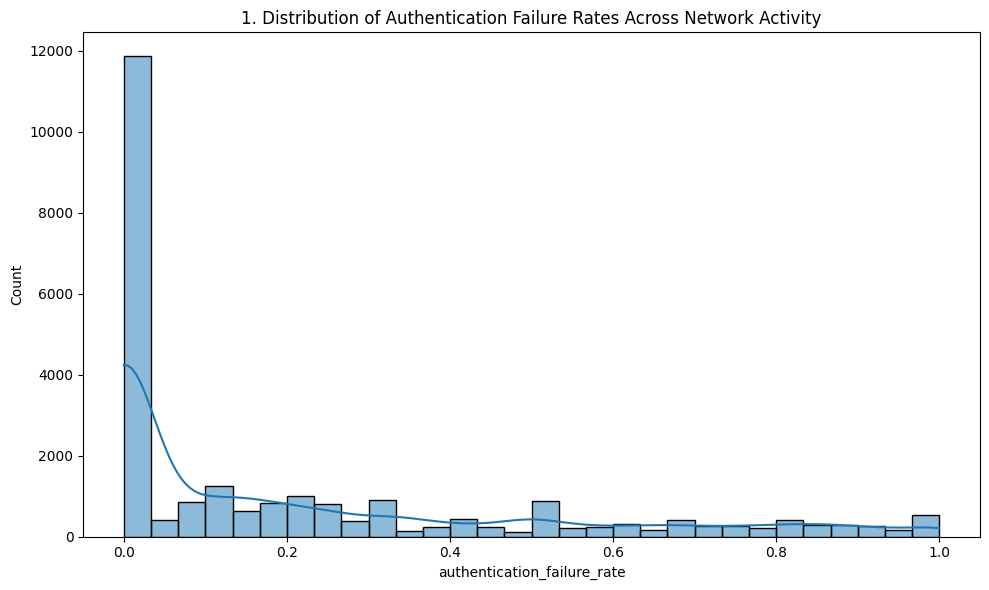

In [13]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='authentication_failure_rate', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Authentication Failure Rates Across Network Activity')
show_fig()
plot_no += 1

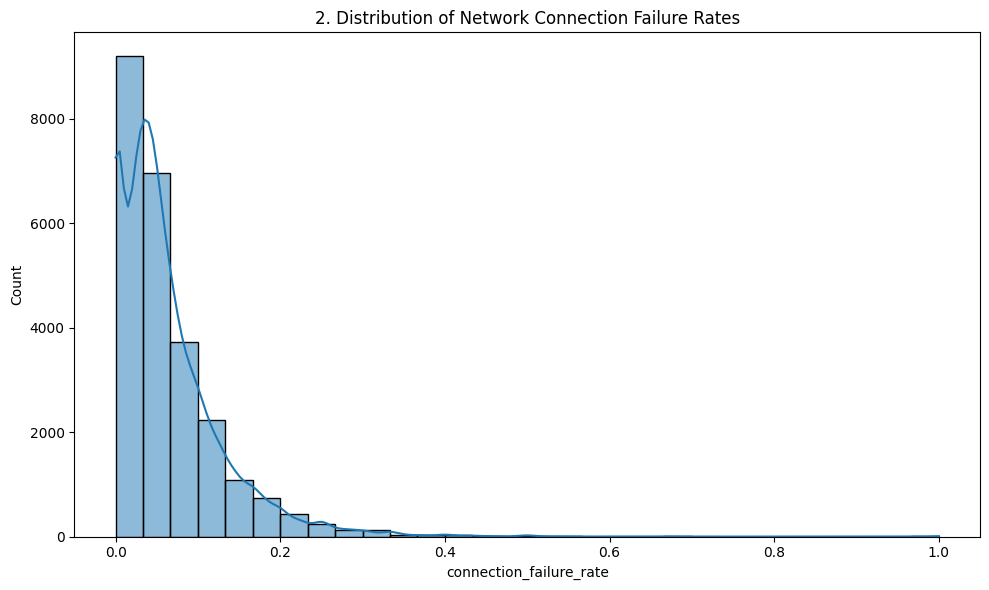

In [14]:
fig = plt.figure(figsize=(10,6))
sns.histplot(data=df, x='connection_failure_rate', kde=True, bins=30)
plt.title(f'{plot_no}. Distribution of Network Connection Failure Rates')
show_fig()
plot_no += 1

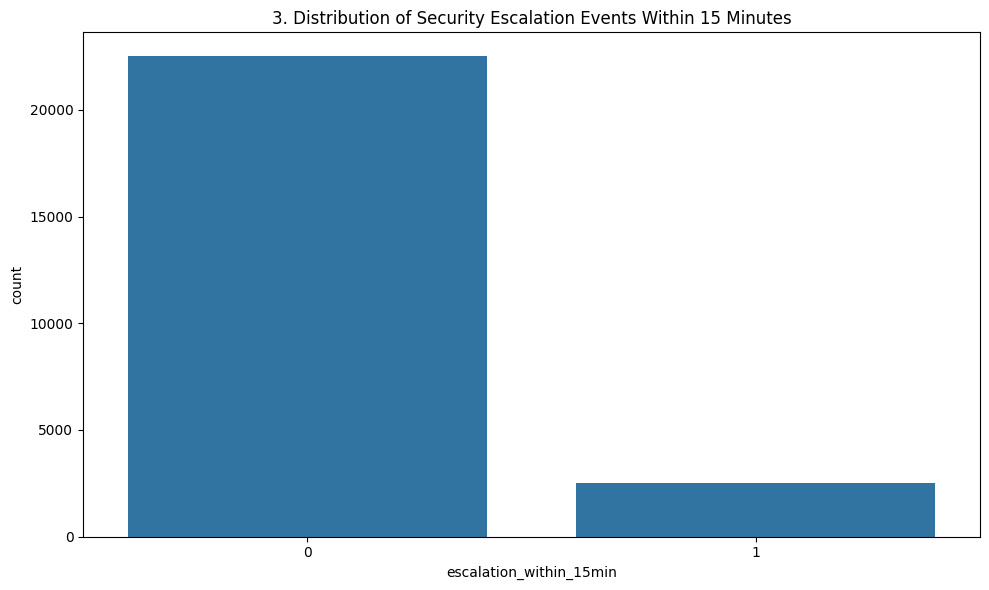

In [15]:
fig = plt.figure(figsize=(10,6))
sns.countplot(data=df, x='escalation_within_15min')
plt.title(f'{plot_no}. Distribution of Security Escalation Events Within 15 Minutes')
show_fig()
plot_no += 1

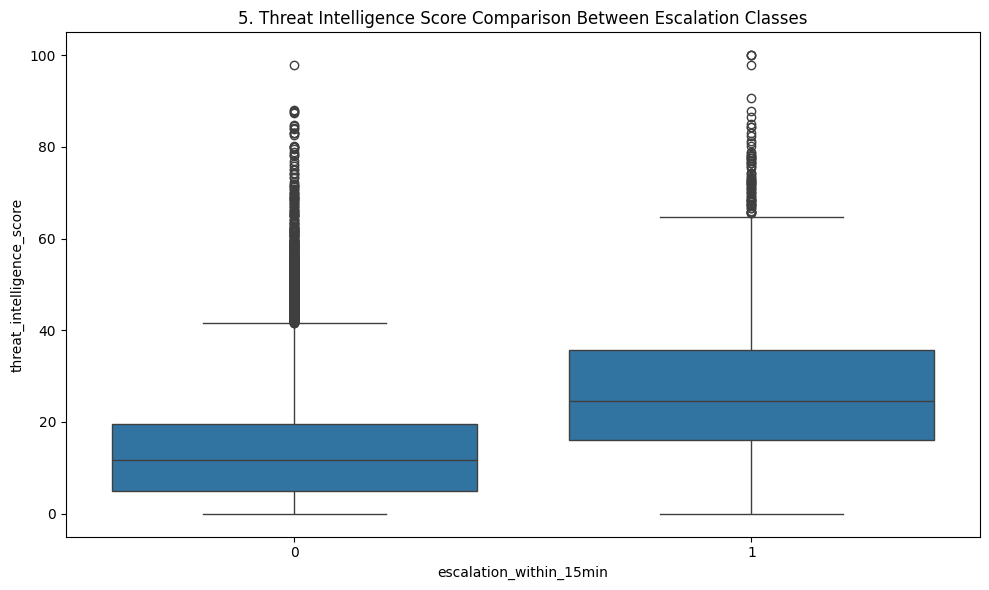

In [17]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='escalation_within_15min', y='threat_intelligence_score')
plt.title(f'{plot_no}. Threat Intelligence Score Comparison Between Escalation Classes')
show_fig()
plot_no += 1

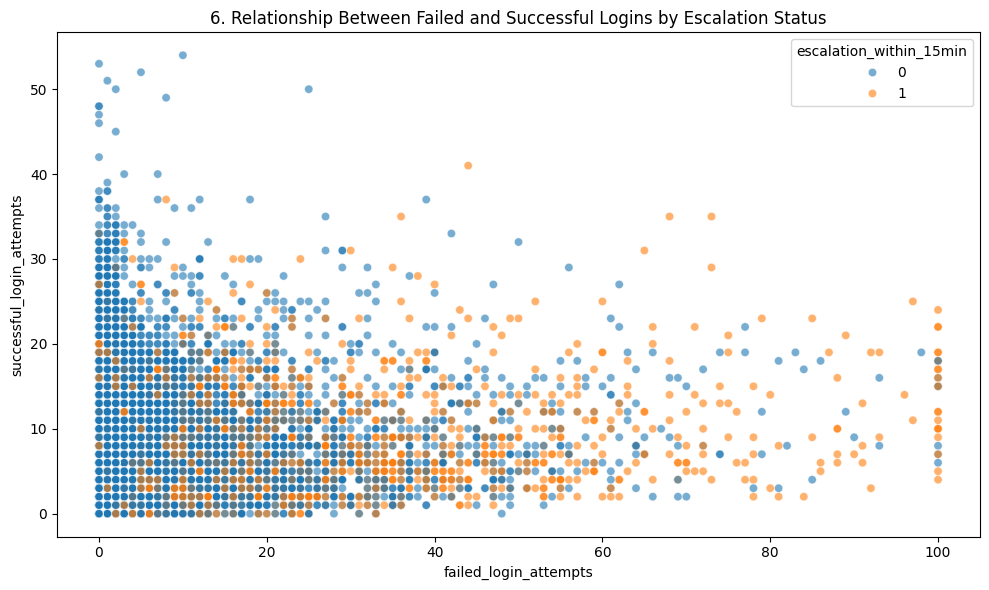

In [18]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='failed_login_attempts', y='successful_login_attempts', hue='escalation_within_15min', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Failed and Successful Logins by Escalation Status')
show_fig()
plot_no += 1

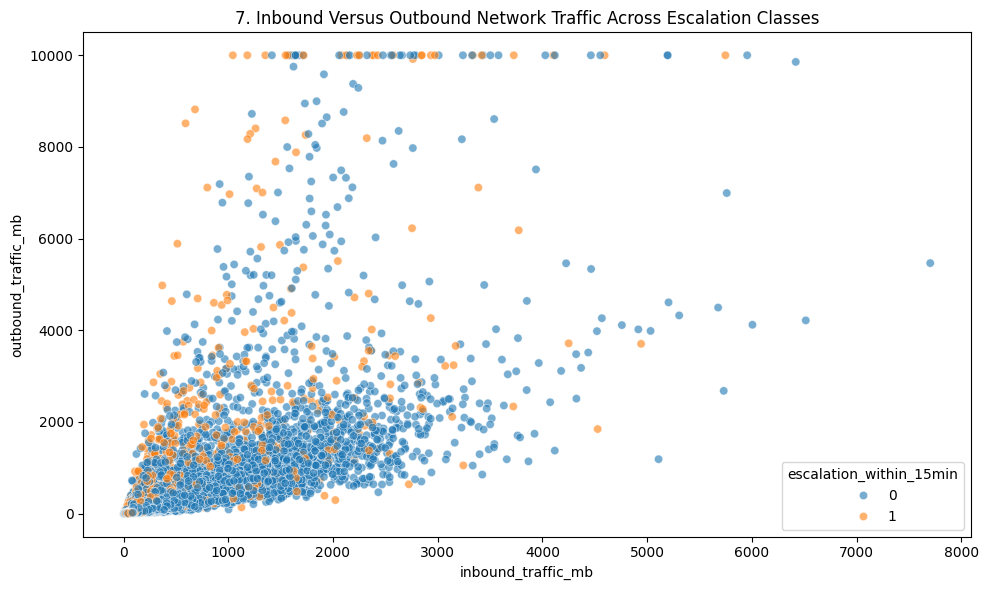

In [19]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='inbound_traffic_mb', y='outbound_traffic_mb', hue='escalation_within_15min', alpha=0.6)
plt.title(f'{plot_no}. Inbound Versus Outbound Network Traffic Across Escalation Classes')
show_fig()
plot_no += 1

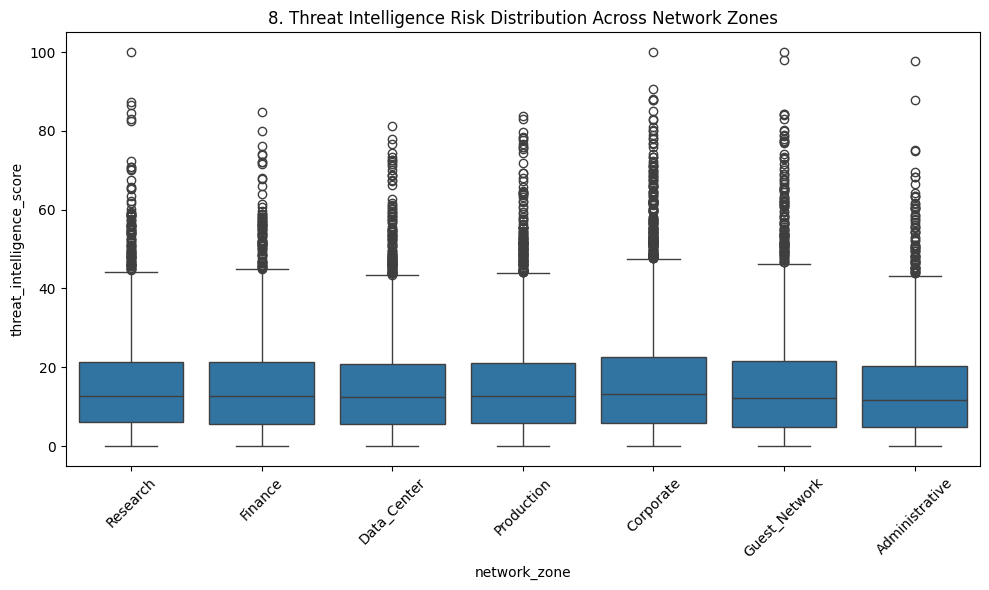

In [20]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='network_zone', y='threat_intelligence_score')
plt.title(f'{plot_no}. Threat Intelligence Risk Distribution Across Network Zones')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

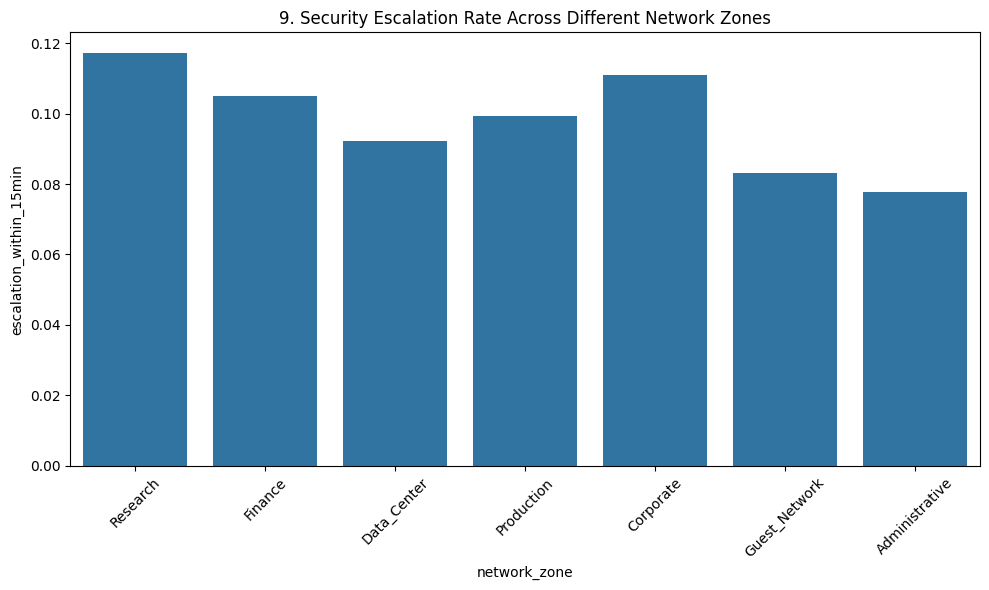

In [21]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='network_zone', y='escalation_within_15min', errorbar=None)
plt.title(f'{plot_no}. Security Escalation Rate Across Different Network Zones')
plt.xticks(rotation=45)
show_fig()
plot_no += 1

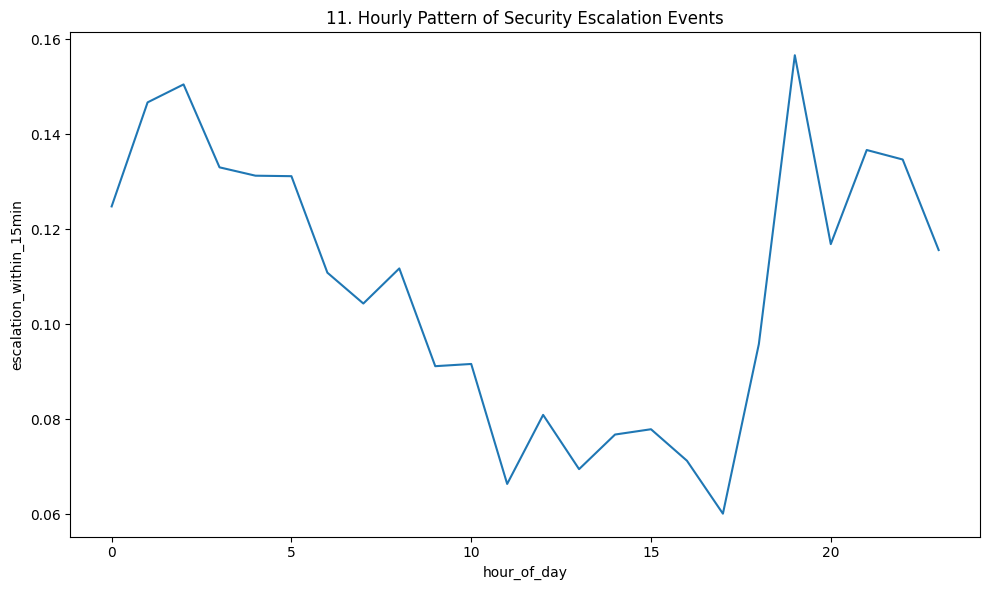

In [23]:
fig = plt.figure(figsize=(10,6))
sns.lineplot(data=df, x='hour_of_day', y='escalation_within_15min', errorbar=None)
plt.title(f'{plot_no}. Hourly Pattern of Security Escalation Events')
show_fig()
plot_no += 1

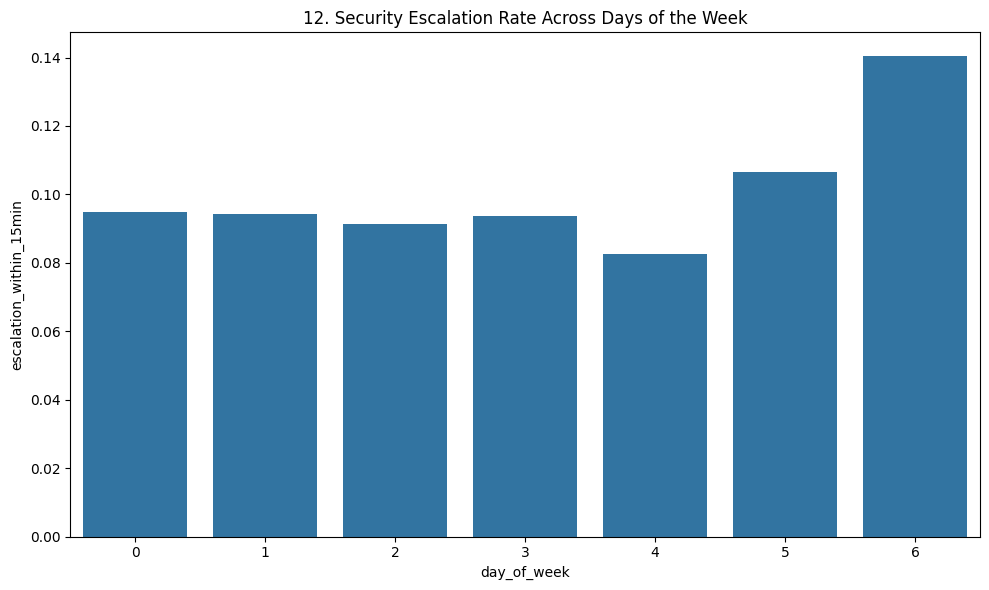

In [24]:
fig = plt.figure(figsize=(10,6))
sns.barplot(data=df, x='day_of_week', y='escalation_within_15min', errorbar=None)
plt.title(f'{plot_no}. Security Escalation Rate Across Days of the Week')
show_fig()
plot_no += 1

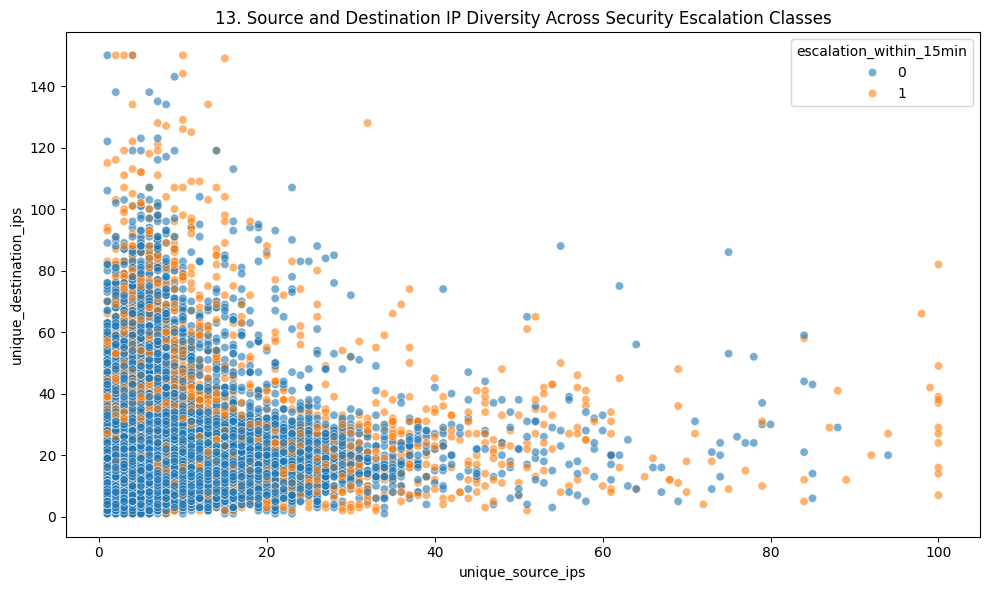

In [25]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='unique_source_ips', y='unique_destination_ips', hue='escalation_within_15min', alpha=0.6)
plt.title(f'{plot_no}. Source and Destination IP Diversity Across Security Escalation Classes')
show_fig()
plot_no += 1

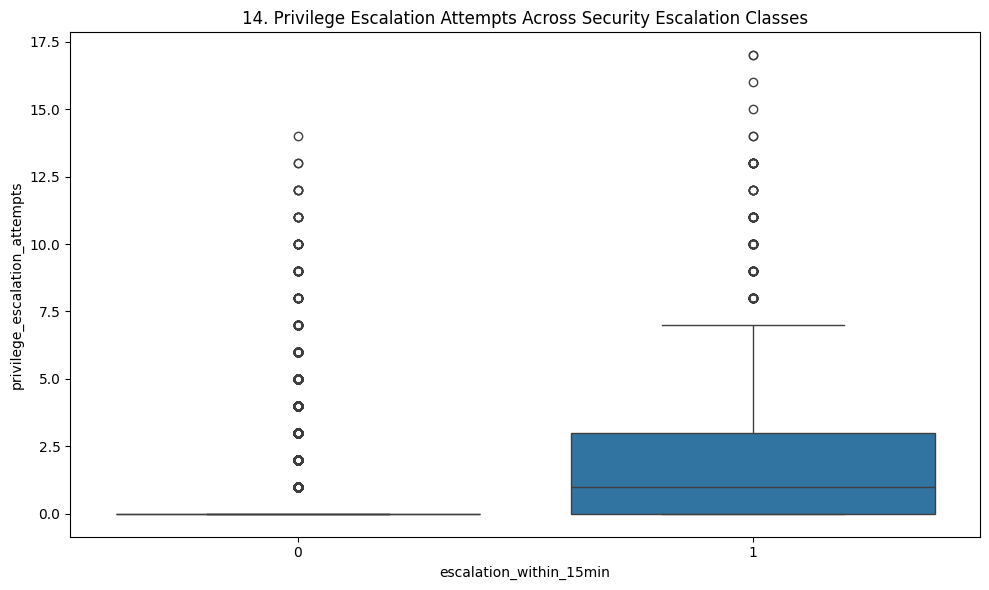

In [26]:
fig = plt.figure(figsize=(10,6))
sns.boxplot(data=df, x='escalation_within_15min', y='privilege_escalation_attempts')
plt.title(f'{plot_no}. Privilege Escalation Attempts Across Security Escalation Classes')
show_fig()
plot_no += 1

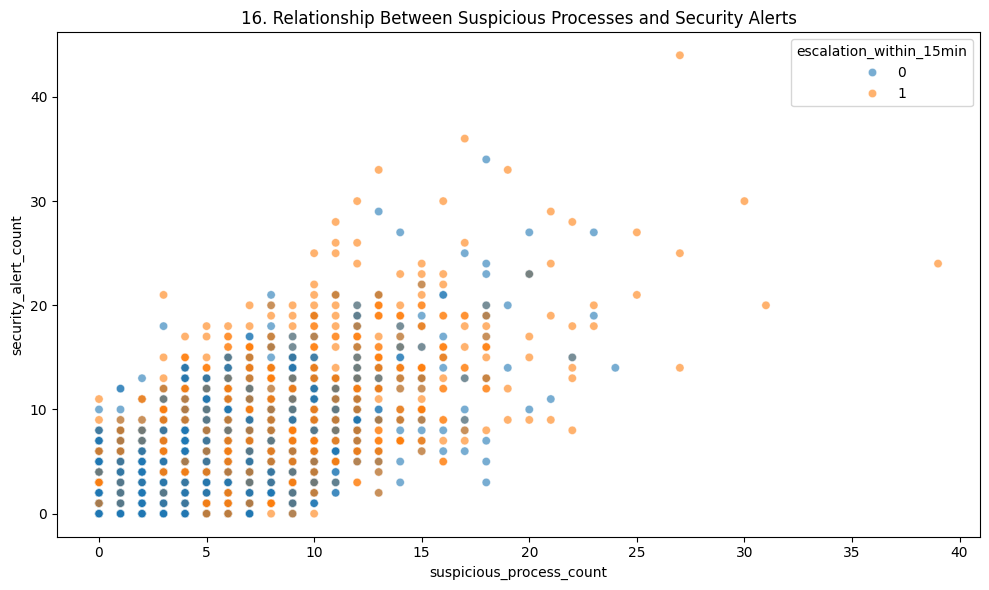

In [28]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='suspicious_process_count', y='security_alert_count', hue='escalation_within_15min', alpha=0.6)
plt.title(f'{plot_no}. Relationship Between Suspicious Processes and Security Alerts')
show_fig()
plot_no += 1

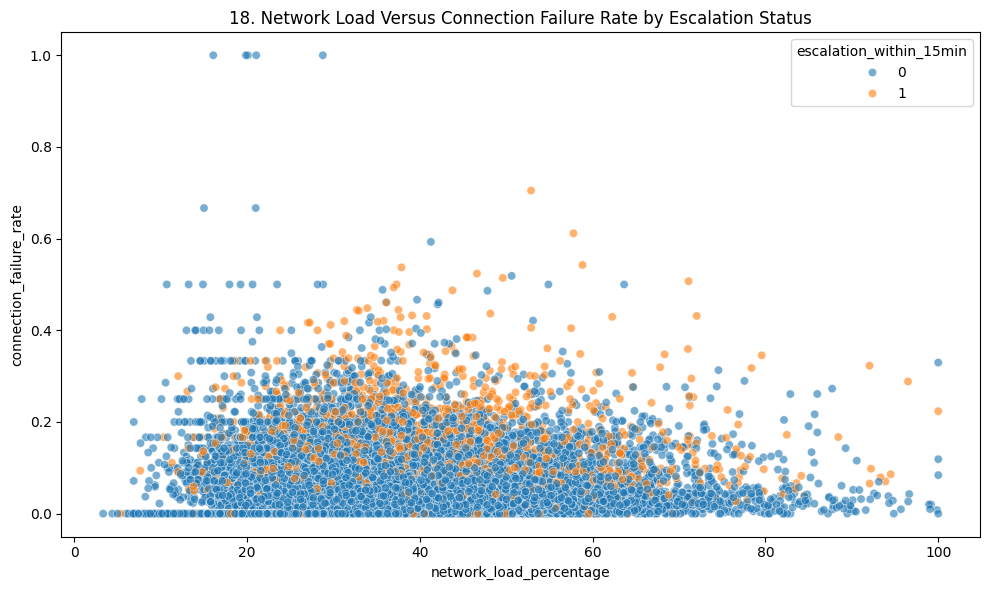

In [30]:
fig = plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='network_load_percentage', y='connection_failure_rate', hue='escalation_within_15min', alpha=0.6)
plt.title(f'{plot_no}. Network Load Versus Connection Failure Rate by Escalation Status')
show_fig()
plot_no += 1

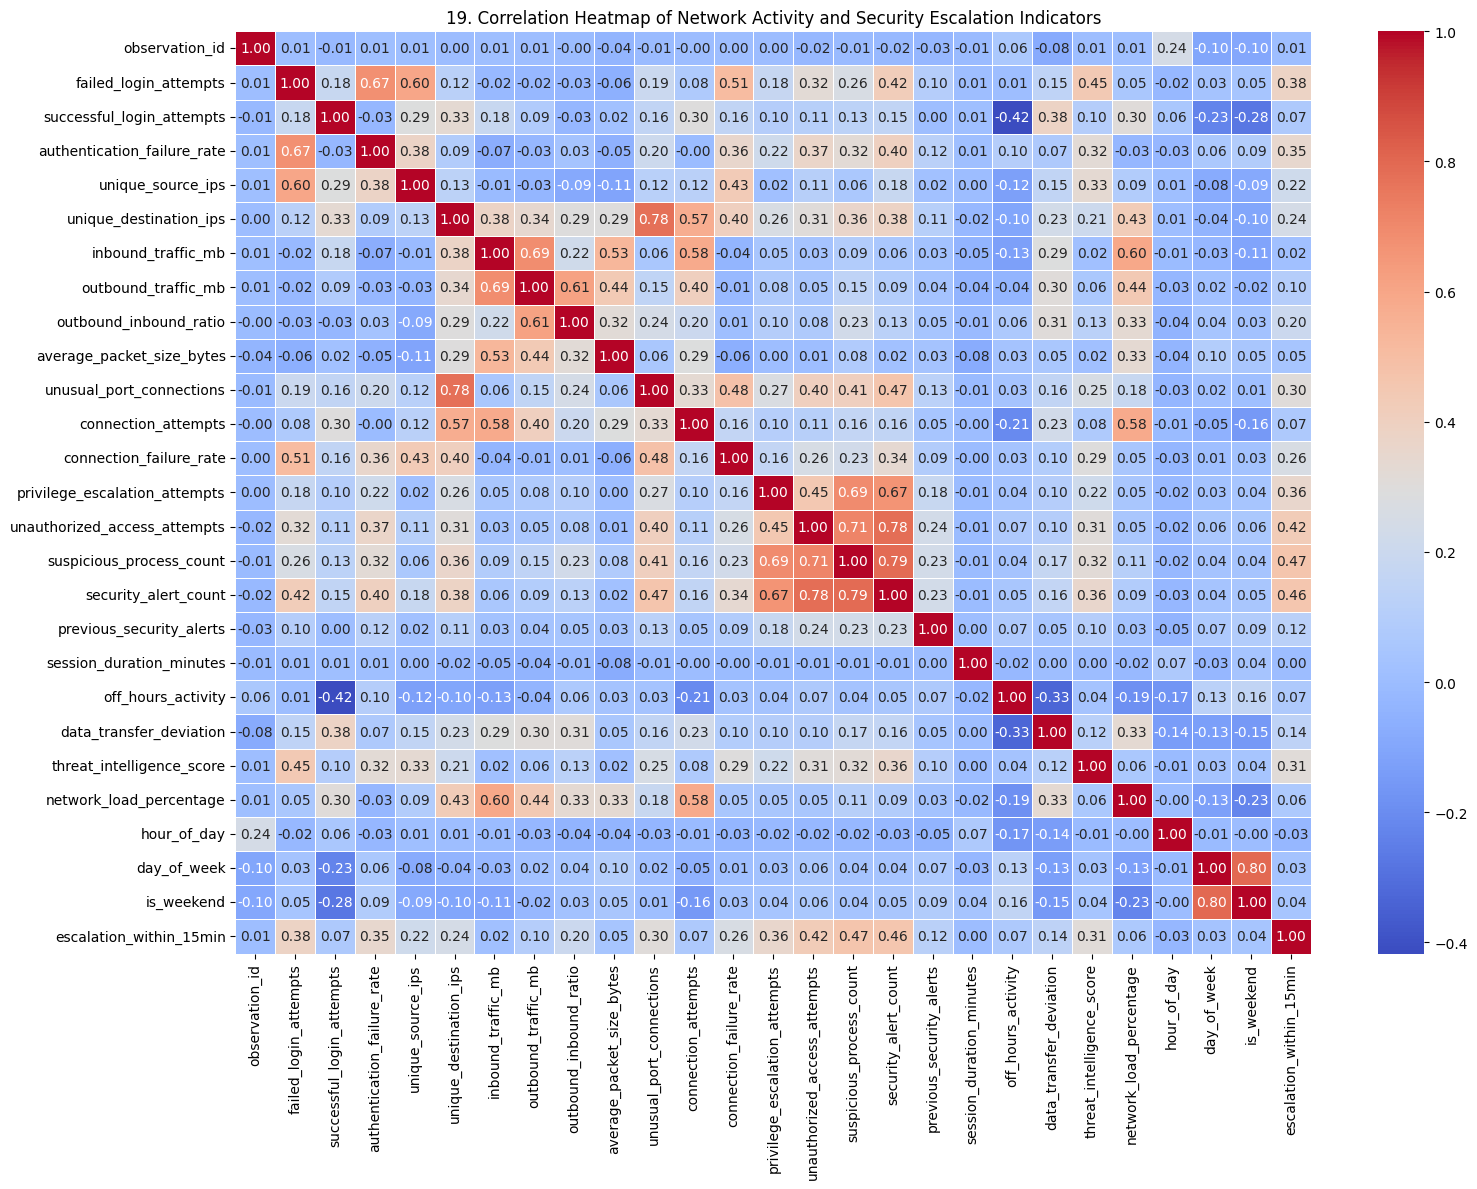

In [31]:
corr = df.select_dtypes(include='number').corr()
fig = plt.figure(figsize=(16,12))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title(f'{plot_no}. Correlation Heatmap of Network Activity and Security Escalation Indicators')
show_fig()
plot_no += 1

# Model Training

## Select useful features

In [32]:
X = df.drop(columns=['escalation_within_15min', 'observation_id', 'timestamp',
                     'network_node_id', 'network_zone', 'activity_session_id'],
            errors='ignore')

y = df['escalation_within_15min']

## Keep numerical features

In [33]:
X = X.select_dtypes(include=np.number)

## Split dataset with balanced class distribution

In [34]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

## Create preprocessing pipeline

In [35]:
pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('model', HistGradientBoostingClassifier(
        max_iter=100,
        learning_rate=0.05,
        max_leaf_nodes=15,
        l2_regularization=2.0,
        min_samples_leaf=30,
        random_state=42
    ))
])

## Calculate class weights

In [36]:
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

## Train model

In [37]:
pipeline.fit(X_train, y_train, model__sample_weight=sample_weights)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('model',
                 HistGradientBoostingClassifier(l2_regularization=2.0,
                                                learning_rate=0.05,
                                                max_leaf_nodes=15,
                                                min_samples_leaf=30,
                                                random_state=42))])

## Make predictions

In [38]:
y_pred = pipeline.predict(X_test)

## Calculate model performance

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, zero_division=0))
print("Recall:", recall_score(y_test, y_pred, zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, zero_division=0))

Accuracy: 0.842
Balanced Accuracy: 0.8738641817380584
Precision: 0.3785357737104825
Recall: 0.9136546184738956
F1 Score: 0.5352941176470588


## Display classification report

In [40]:
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))


Classification Report:

              precision    recall  f1-score   support

           0       0.99      0.83      0.90      4502
           1       0.38      0.91      0.54       498

    accuracy                           0.84      5000
   macro avg       0.68      0.87      0.72      5000
weighted avg       0.93      0.84      0.87      5000



## Plot confusion matrix

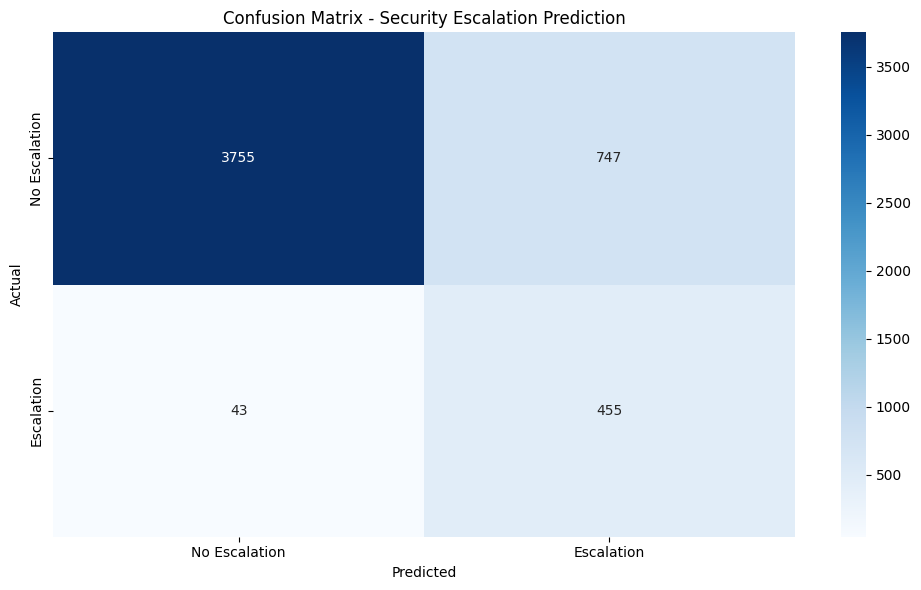

In [41]:
fig = plt.figure(figsize=(10,6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['No Escalation', 'Escalation'],
            yticklabels=['No Escalation', 'Escalation'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Security Escalation Prediction')
show_fig()